In [1]:
import os

import pandas as pd
import numpy as np
from collections import Counter
from scipy.stats import spearmanr

from ot import sliced_wasserstein_distance
import random
import itertools
import matplotlib.pyplot as plt
import seaborn as sns
from cluster_weather_years.functions import (
    build_df_centroids,
    build_df_random,
)
from cluster_weather_years.constants import (
    BASE_OUTPUT,
    MODELS,
    HYDROLOGICAL_YEARS,
    COUNTRIES,
    SEASONS,
)
from cluster_weather_years.evaluation import qq_univariate_rmse

from sa_settings import MATCH_COUNTRIES

from tqdm.notebook import tqdm

In [6]:
# Config
NUM_CLUSTERS = 30  # hardcode
NUM_CLUSTERS_LARGE_SMALL = 5  # hardcode, 30 years if main one is 5y and vice versa

# RUN_ID_MAIN = "NL_20251024_1320"  # NL, 30 years
# LABEL_RUN_ID_MAIN = "SA, NL 30y"
# RUN_ID_MAIN = "NL_20251112_1638"  # NL, 30y seasonal, incl. residual load
RUN_ID_MAIN = (
    "all_countries_full_vars_20251201_1557"  # full countries, 30y seasonal, incl. rl
)
LABEL_RUN_ID_MAIN = "SA Seasonal, all-countries 30y"

LABEL_RUN_ID_MAIN_RANDOM = f"Random {NUM_CLUSTERS}y"
# RUN_ID_MAIN = "NL_20251023_0942"  # NL, 5 years
# RUN_ID_MAIN = "NL_20251125_1454"  # NL, 5 yy seasonal, incl. residual load
# LABEL_RUN_ID_MAIN = "SA, NL 5y"
# RUN_ID_alternative = "NL_20251024_1320_5y_subset"  # 5y subsample from 30y sample
# RUN_ID_alternative = "NL_20251111_1601"  # NL, 30y, seasonal_wasserstein
RUN_ID_ALTERNATIVE = "NL_20251112_1638"  # NL, 30y seasonal, incl. residual load
LABEL_RUN_ID_ALTERNATIVE = "SA Seasonal, NL 30y"

# RUN_ID_LARGE_SMALL = "NL_20251024_1320"  # 30 years if main one is 5y and vice versa
RUN_ID_LARGE_SMALL = "NL_20251023_0942"  # 30 years if main one is 5y and vice versa
LABEL_RUN_ID_LARGE_SMALL = "SA, NL 5y subset"
LABEL_RUN_ID_LARGE_SMALL_RANDOM = "Random 5y subset"

FNAME_KMEDOIDS = "centroid_years_load_30yr.csv"  # K-medoids run to compare to
# FNAME_KMEDOIDS = "centroid_years_load.csv"  # K-medoids run to compare to
FNAME_KMEDOIDS_LARGE_SMALL = (
    "centroid_years_load.csv"  # 5yr K-medoids run if main one is 30y and vice versa
)
LABEL_KMEDOIDS = "K-medoids, NL 30y"
# LABEL_KMEDOIDS = "K-medoids, NL 5y"

LABEL_MLZ = "MLZ-25 36y"

seed = 42
random.seed(seed)

# 1. Build dataframes

In [3]:
# build df
# DF_PROD_DEMAND_FNAME = os.path.join(
#     BASE_OUTPUT, "dataframes/df_prod_demand_daily_multi_country_WRONG_CAPACITIES.csv"
# )
FNAME_PROD_DEMAND = "dataframes/df_prod_demand_daily_all_countries_WRONG_DEMAND.csv"
DF_PROD_DEMAND_FNAME = os.path.join(BASE_OUTPUT, FNAME_PROD_DEMAND)

SA_OUTPUT_DIR = os.path.join(BASE_OUTPUT, "simulated_annealing")

df_daily = pd.read_csv(DF_PROD_DEMAND_FNAME, index_col=0)
df_daily["Date"] = pd.to_datetime(df_daily["Date"])
df_daily = df_daily.query("Hydrological_year > 2014 and Hydrological_year < 2044")

vars_to_match = []
for country in MATCH_COUNTRIES:
    vars_to_match.extend(
        [
            f"{country}_OFF_prod",
            f"{country}_ON_prod",
            f"{country}_SOLAR_prod",
            f"{country}_Demand",
            f"{country}_Residual_load",
        ]
    )

vars_to_plot = vars_to_match + [f"Multi RMSE {country}" for country in MATCH_COUNTRIES]

all_vars = df_daily.columns[3:-1].values

# settings for random-draws
df_idx = df_daily.set_index(["model", "Hydrological_year"]).sort_index()
keys = df_idx.index.unique().to_numpy()
rng = np.random.default_rng(seed)

In [7]:
df_selections_main = pd.read_csv(
    os.path.join(SA_OUTPUT_DIR, f"run_{RUN_ID_MAIN}/results_grid.csv"), index_col=0
)

df_sel_main = df_selections_main.query(
    "optimized_metric == 'wasserstein_seasonal_score'"
).sort_values("best_score", ascending=True)

# alternative one is for comparison
# df_selections_alternative = pd.read_csv(
#     os.path.join(SA_OUTPUT_DIR, f"subsampling/{RUN_ID_alternative}/results_grid.csv"),
#     index_col=0,
# )
# df_sel_alternative_sa = df_selections_alternative.query(
#     "optimized_metric == 'wasserstein_score'"
# ).sort_values("best_score", ascending=True)

df_selections_alternative = pd.read_csv(
    os.path.join(SA_OUTPUT_DIR, f"run_{RUN_ID_ALTERNATIVE}/results_grid.csv"),
    index_col=0,
)
df_sel_alternative_sa = df_selections_alternative.query(
    "optimized_metric == 'wasserstein_seasonal_score'"
).sort_values("best_score", ascending=True)

df_selections_large = pd.read_csv(
    os.path.join(SA_OUTPUT_DIR, f"run_{RUN_ID_LARGE_SMALL}/results_grid.csv"),
    index_col=0,
)

df_sel_large = df_selections_large.query(
    "optimized_metric == 'wasserstein_score'"
).sort_values("best_score", ascending=True)

centroids_k_medoids_load = pd.read_csv(
    os.path.join(BASE_OUTPUT, f"centroids/{FNAME_KMEDOIDS}"), index_col=0
)
centroids_k_medoids_load_sel = centroids_k_medoids_load[
    ["model", "Hydrological_year"]
].values

In [8]:
mlz_models = ["cmcc_cm2_sr5", "ec_earth3", "mpi_esm_1_2_hr"]
mlz_years = range(2025, 2037)
# combine these models and years into tuples
mlz_modelyears = list(itertools.product(mlz_models, mlz_years))

# 2. Define functions

In [9]:
def build_df_random_large(df_daily, size):
    """
    Build a dataframe with random model-year combinations of arbritary size. To set a benchmark
    """
    model_years = list(itertools.product(MODELS, HYDROLOGICAL_YEARS))
    random_models_years = random.sample(model_years, k=size)

    frames_random = []
    for model_random, year_random in random_models_years:
        df_random = df_daily.query(
            f"model == '{model_random}' and Hydrological_year == {year_random}"
        )
        frames_random.append(df_random)
    return pd.concat(frames_random, ignore_index=True)

In [10]:
def qq_multi_rmse(df_metrics):
    # Add Multi RMSE column which is the average of RMSE for the specified variables
    df_metrics_with_multi = df_metrics.copy()

    # Calculate Multi RMSE for each dataset
    multi_rmse_values = []
    full_rmse_values = []

    for dataset in df_metrics["dataset"].unique():
        dataset_metrics = df_metrics[df_metrics["dataset"] == dataset]
        country_rmse = []
        for country in COUNTRIES:
            multi_rmse_vars = [
                f"{country}_OFF_prod",
                f"{country}_ON_prod",
                f"{country}_SOLAR_prod",
                f"{country}_Demand",
                f"{country}_Residual_load",  # NOTE: JUST ADDED!!
            ]
            multi_rmse = dataset_metrics[
                dataset_metrics["variable"].isin(multi_rmse_vars)
            ]["RMSE"].mean()
            country_rmse.append(multi_rmse)
            multi_rmse_values.append(
                {
                    "dataset": dataset,
                    "variable": f"Multi RMSE {country}",
                    "RMSE": multi_rmse,
                }
            )
        full_rmse_values.append(
            {
                "dataset": dataset,
                "variable": "Multi RMSE Full",
                "RMSE": np.array(country_rmse).mean(),
            }
        )

    # Add Multi RMSE rows to the dataframe
    multi_rmse_df = pd.DataFrame(multi_rmse_values)
    full_rmse_df = pd.DataFrame(full_rmse_values)
    df_metrics_with_multi = pd.concat(
        [df_metrics, multi_rmse_df, full_rmse_df], ignore_index=True
    )
    return df_metrics_with_multi

# 3. Build datasets and calculate metrics

In [11]:
# build datasets to compare

columns = all_vars.copy()

# Create datasets dictionary with all available selections from df_sel_combined
datasets = {}

for i in range(len(df_sel_main)):
    datasets[f"{LABEL_RUN_ID_MAIN} {i + 1}"] = build_df_centroids(
        df_daily, eval(df_sel_main.iloc[i]["selected"])
    )

    datasets[f"{LABEL_RUN_ID_LARGE_SMALL} {i + 1}"] = build_df_centroids(
        df_daily, eval(df_sel_large.iloc[i]["selected"])
    )

    datasets[f"{LABEL_RUN_ID_MAIN_RANDOM} {i + 1}"] = build_df_random(
        df_idx, keys, rng, num_random=NUM_CLUSTERS
    )

    datasets[f"{LABEL_RUN_ID_LARGE_SMALL_RANDOM} {i + 1}"] = build_df_random(
        df_idx, keys, rng, num_random=NUM_CLUSTERS_LARGE_SMALL
    )

for i in range(len(df_sel_alternative_sa)):
    datasets[f"{LABEL_RUN_ID_ALTERNATIVE} {i + 1}"] = build_df_centroids(
        df_daily, eval(df_sel_alternative_sa.iloc[i]["selected"])
    )

datasets[f"{LABEL_KMEDOIDS} 1"] = build_df_centroids(
    df_daily, centroids_k_medoids_load_sel, mode="Hydrological_year"
)

datasets["MLZ-25 1"] = build_df_centroids(
    df_daily, mlz_modelyears, mode="Calendar_year"
)

sizes = [
    5,
    10,
    25,
    50,
    90,
    120,
    150,
    174,
]  # 174 is full dataset, because of hydrological years!

for size in sizes:
    datasets[f"Large Random {size}"] = build_df_random_large(df_daily, size)

In [12]:
# calc univariate metrics

df_metrics = qq_univariate_rmse(df_daily, datasets, columns)
# add multivariate metrics
df_metrics = qq_multi_rmse(df_metrics)

# add dataset-type column
df_metrics["dataset_type"] = (
    df_metrics["dataset"].str.replace(r"\s*\d+\s*$", "", regex=True).str.strip()
)

In [13]:
# compute Wasserstein
# TODO: make disjoint
ds_ref = df_daily[vars_to_match].to_numpy()

df_wasserstein = pd.DataFrame(index=datasets.keys(), columns=["Wasserstein_distance"])
for dataset in tqdm(datasets):
    ds_sel = datasets[dataset][vars_to_match].to_numpy()
    df_wasserstein.loc[dataset, "Wasserstein_distance"] = sliced_wasserstein_distance(
        ds_sel, ds_ref, seed=seed, n_projections=50
    )

df_wasserstein["dataset_type"] = (
    df_wasserstein.index.to_series()
    .str.replace(r"\s*\d+\s*$", "", regex=True)
    .str.strip()
)

  0%|          | 0/235 [00:00<?, ?it/s]

# 4. Perform comparison

## 4.1 Country-wide comparison

/tmp/ipykernel_3545239/3252007718.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  country_data_main_vs_random["country"] = country_data_main_vs_random["variable"].str.split().str[-1]
/tmp/ipykernel_3545239/3252007718.py:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  country_data_k_medoids["country"] = country_data_k_medoids["variable"].str.split().str[-1]
/tmp/ipykernel_3545239/3252007718.py:14: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc

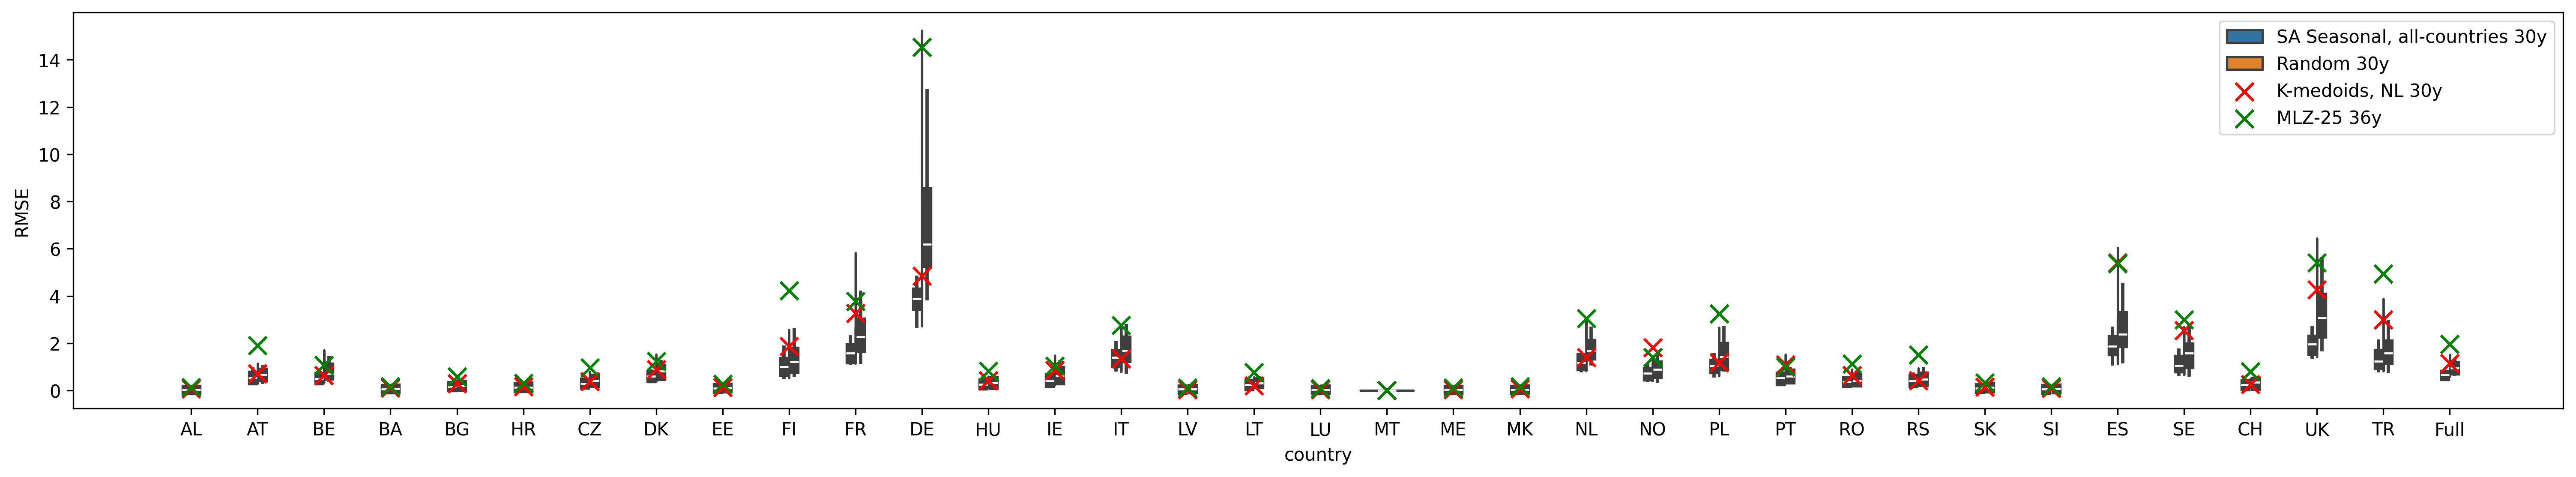

In [ ]:
# violin plot comparing main SA vs random draw

country_data_main_vs_random = df_metrics.query(
    "dataset_type in [@LABEL_RUN_ID_MAIN, @LABEL_RUN_ID_MAIN_RANDOM] and variable.str.contains('Multi')"
)
country_data_main_vs_random["country"] = (
    country_data_main_vs_random["variable"].str.split().str[-1]
)
country_data_k_medoids = df_metrics.query(
    "dataset_type == @LABEL_KMEDOIDS and variable.str.contains('Multi')"
)
country_data_k_medoids["country"] = (
    country_data_k_medoids["variable"].str.split().str[-1]
)
country_data_mlz = df_metrics.query(
    "dataset_type == 'MLZ-25' and variable.str.contains('Multi')"
)
country_data_mlz["country"] = country_data_mlz["variable"].str.split().str[-1]
fig, ax = plt.subplots(figsize=(25, 4), dpi=300)

# Create violin plot with split violins
sns.violinplot(
    data=country_data_main_vs_random,
    x="country",
    y="RMSE",
    hue="dataset_type",
    split=True,
    ax=ax,
    cut=0,
)
ax.scatter(
    country_data_k_medoids["country"],
    country_data_k_medoids["RMSE"],
    color="red",
    marker="x",
    s=100,
    label=LABEL_KMEDOIDS,
    zorder=5,
)
ax.scatter(
    country_data_mlz["country"],
    country_data_mlz["RMSE"],
    color="green",
    marker="x",
    s=100,
    label=LABEL_MLZ,
    zorder=5,
)
ax.legend()

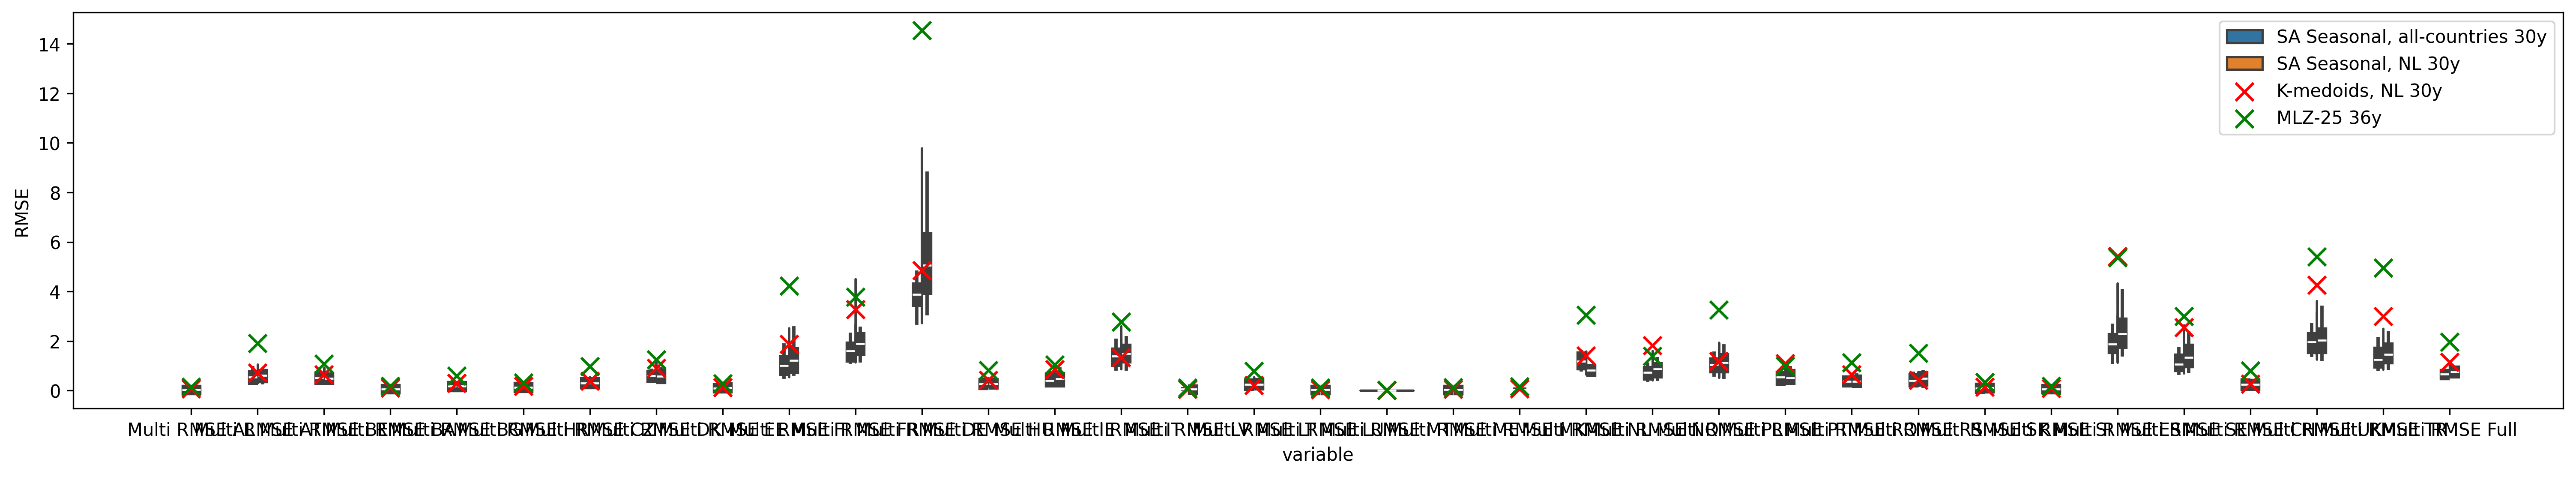

In [15]:
# violin comparing two SA versions

country_data_main_vs_alternative = df_metrics.query(
    "dataset_type in [@LABEL_RUN_ID_MAIN, @LABEL_RUN_ID_ALTERNATIVE] and variable.str.contains('Multi')"
)

fig, ax = plt.subplots(figsize=(25, 4), dpi=300)
# Create violin plot with split violins
sns.violinplot(
    data=country_data_main_vs_alternative,
    x="variable",
    y="RMSE",
    hue="dataset_type",
    split=True,
    ax=ax,
    cut=0,
)
ax.scatter(
    country_data_k_medoids["variable"],
    country_data_k_medoids["RMSE"],
    color="red",
    marker="x",
    s=100,
    label=LABEL_KMEDOIDS,
    zorder=5,
)
ax.scatter(
    country_data_mlz["variable"],
    country_data_mlz["RMSE"],
    color="green",
    marker="x",
    s=100,
    label=LABEL_MLZ,
    zorder=5,
)
ax.legend()

## 4.2 Univariate comparison

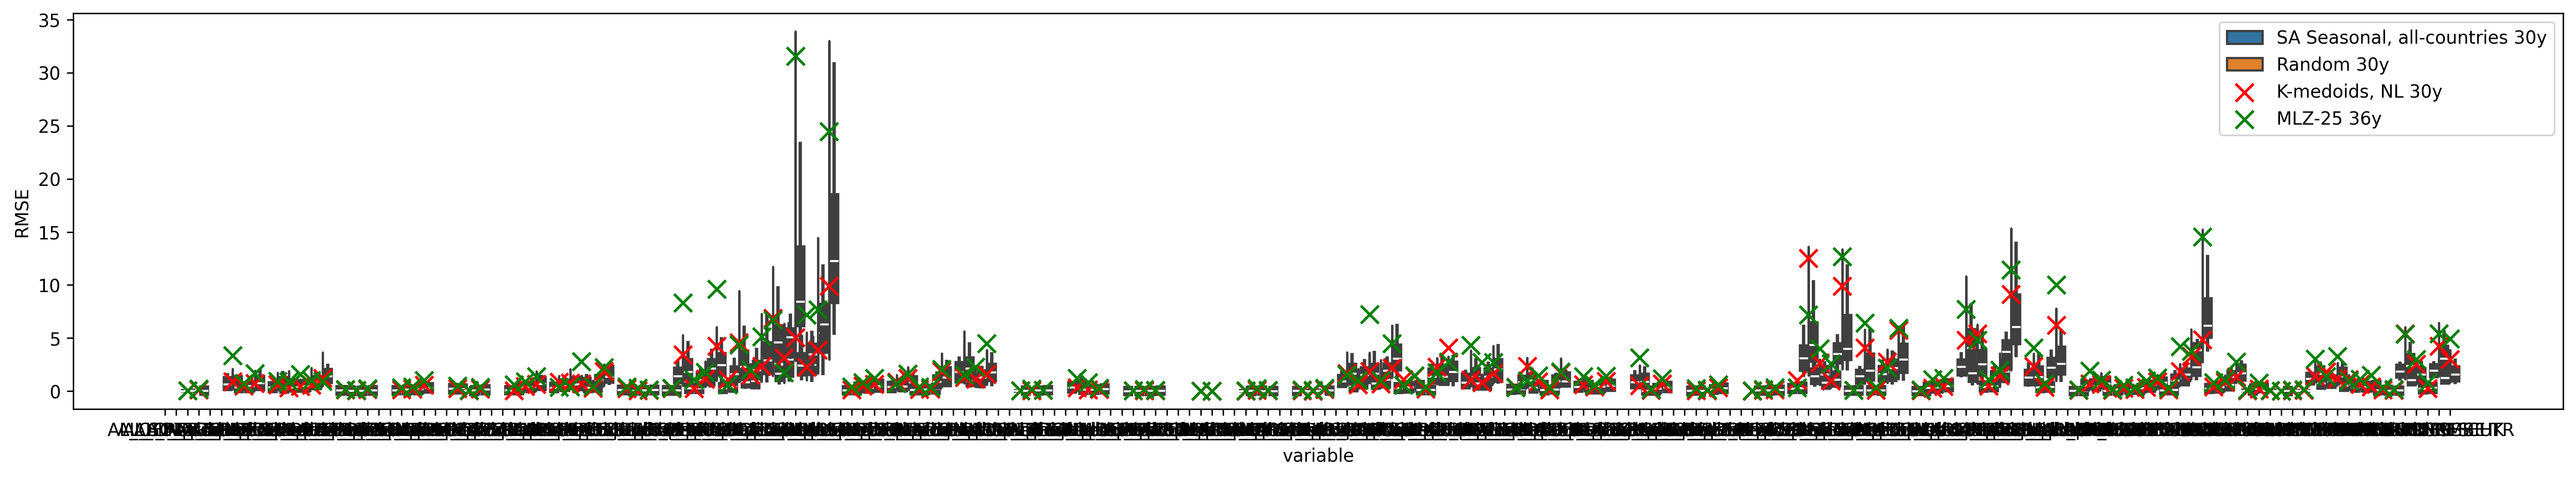

In [16]:
uni_data_main_vs_random = df_metrics.query(
    "dataset_type in [@LABEL_RUN_ID_MAIN, @LABEL_RUN_ID_MAIN_RANDOM] and variable in @vars_to_plot"
)
uni_data_k_medoids = df_metrics.query(
    "dataset_type == @LABEL_KMEDOIDS and variable in @vars_to_plot"
)
uni_data_mlz = df_metrics.query(
    "dataset_type == 'MLZ-25' and variable in @vars_to_plot"
)

fig, ax = plt.subplots(figsize=(25, 4), dpi=300)

# Create violin plot with split violins
sns.violinplot(
    data=uni_data_main_vs_random,
    x="variable",
    y="RMSE",
    hue="dataset_type",
    split=True,
    ax=ax,
    cut=0,
)
ax.scatter(
    uni_data_k_medoids["variable"],
    uni_data_k_medoids["RMSE"],
    color="red",
    marker="x",
    s=100,
    label=LABEL_KMEDOIDS,
    zorder=5,
)
ax.scatter(
    uni_data_mlz["variable"],
    uni_data_mlz["RMSE"],
    color="green",
    marker="x",
    s=100,
    label=LABEL_MLZ,
    zorder=5,
)
ax.legend()


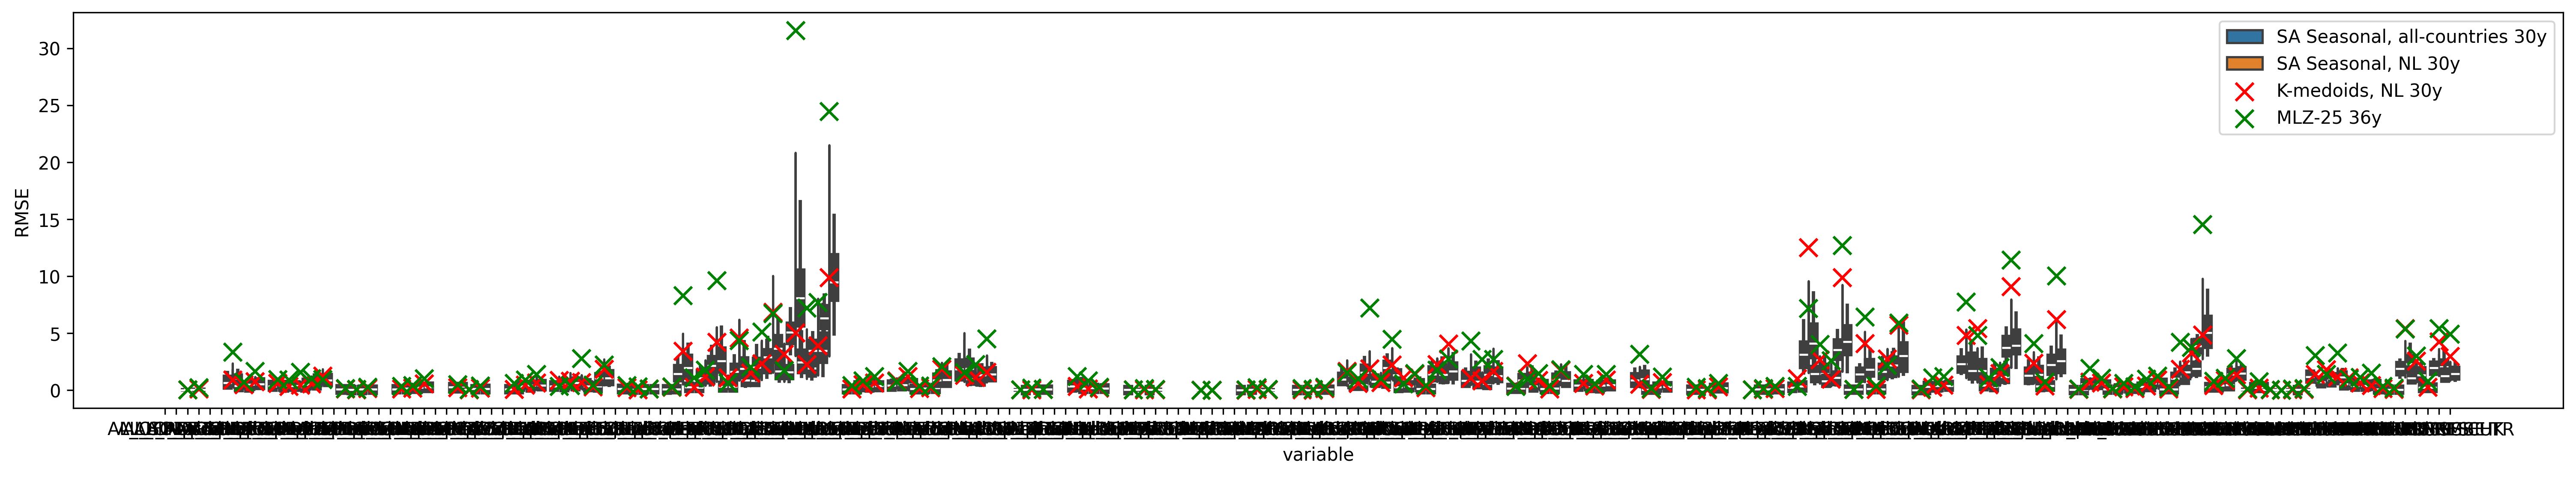

In [17]:
uni_data_main_vs_alternative = df_metrics.query(
    "dataset_type in [@LABEL_RUN_ID_MAIN, @LABEL_RUN_ID_ALTERNATIVE] and variable in @vars_to_plot"
)

fig, ax = plt.subplots(figsize=(25, 4), dpi=300)

# Create violin plot with split violins
sns.violinplot(
    data=uni_data_main_vs_alternative,
    x="variable",
    y="RMSE",
    hue="dataset_type",
    split=True,
    ax=ax,
    cut=0,
)
ax.scatter(
    uni_data_k_medoids["variable"],
    uni_data_k_medoids["RMSE"],
    color="red",
    marker="x",
    s=100,
    label=LABEL_KMEDOIDS,
    zorder=5,
)
ax.scatter(
    uni_data_mlz["variable"],
    uni_data_mlz["RMSE"],
    color="green",
    marker="x",
    s=100,
    label=LABEL_MLZ,
    zorder=5,
)
ax.legend()

## 4.3 Wasserstein comparison

In [18]:
# main SA vs random
wass_main_vs_random = df_wasserstein.query(
    "dataset_type in [@LABEL_RUN_ID_MAIN, @LABEL_RUN_ID_MAIN_RANDOM]"
)

fig, ax = plt.subplots(figsize=(8, 4), dpi=300)
sns.violinplot(
    data=wass_main_vs_random,
    hue="dataset_type",
    y="Wasserstein_distance",
    ax=ax,
    cut=0,
    split=True,
)
ax.scatter(
    0,
    df_wasserstein.query("dataset_type == @LABEL_KMEDOIDS")[
        "Wasserstein_distance"
    ].values[0],
    color="red",
    marker="x",
    s=100,
    label=LABEL_KMEDOIDS,
    zorder=5,
)
ax.scatter(
    0,
    df_wasserstein.query("dataset_type == 'MLZ-25'")["Wasserstein_distance"].values[0],
    color="green",
    marker="x",
    s=100,
    label=LABEL_MLZ,
    zorder=5,
)
ax.legend()
ax.set_ylabel("Wasserstein distance (-)")
ax.set_ylim(0, None)

(0.0, 0.05500000000000001)

Error in callback <function _draw_all_if_interactive at 0x7ff96c12fc40> (for post_execute), with arguments args (),kwargs {}:


ConversionError: Failed to convert value(s) to axis units: masked_array(data=[--],
             mask=[ True],
       fill_value=1e+20,
            dtype=float64)

ConversionError: Failed to convert value(s) to axis units: masked_array(data=[--],
             mask=[ True],
       fill_value=1e+20,
            dtype=float64)

<Figure size 2400x1200 with 1 Axes>

In [19]:
# main SA vs random
wass_main_vs_alternative = df_wasserstein.query(
    "dataset_type in [@LABEL_RUN_ID_MAIN, @LABEL_RUN_ID_ALTERNATIVE]"
)

fig, ax = plt.subplots(figsize=(8, 4), dpi=300)
sns.violinplot(
    data=wass_main_vs_alternative,
    hue="dataset_type",
    y="Wasserstein_distance",
    ax=ax,
    cut=0,
    split=True,
)
ax.scatter(
    0,
    df_wasserstein.query("dataset_type == @LABEL_KMEDOIDS")[
        "Wasserstein_distance"
    ].values[0],
    color="red",
    marker="x",
    s=100,
    label=LABEL_KMEDOIDS,
    zorder=5,
)
ax.scatter(
    0,
    df_wasserstein.query("dataset_type == 'MLZ-25'")["Wasserstein_distance"].values[0],
    color="green",
    marker="x",
    s=100,
    label=LABEL_MLZ,
    zorder=5,
)
ax.legend()
ax.set_ylabel("Wasserstein distance (-)")
ax.set_ylim(0, None)

(0.0, 0.05500000000000001)

Error in callback <function _draw_all_if_interactive at 0x7ff96c12fc40> (for post_execute), with arguments args (),kwargs {}:


ConversionError: Failed to convert value(s) to axis units: masked_array(data=[--],
             mask=[ True],
       fill_value=1e+20,
            dtype=float64)

ConversionError: Failed to convert value(s) to axis units: masked_array(data=[--],
             mask=[ True],
       fill_value=1e+20,
            dtype=float64)

<Figure size 2400x1200 with 1 Axes>

## 4.4 Seasonal-comparison

In [20]:
df_wasserstein_seasonal = pd.DataFrame(
    index=datasets.keys(), columns=["Wass_summer", "Wass_winter"]
)
ds_ref_summer = df_daily.query("Date.dt.month in @SEASONS['Summer']")[
    vars_to_match
].to_numpy()
ds_ref_winter = df_daily.query("Date.dt.month in @SEASONS['Winter']")[
    vars_to_match
].to_numpy()

for dataset in tqdm(datasets):
    ds_sel_summer = (
        datasets[dataset]
        .query("Date.dt.month in @SEASONS['Summer']")[vars_to_match]
        .to_numpy()
    )
    ds_sel_winter = (
        datasets[dataset]
        .query("Date.dt.month in @SEASONS['Winter']")[vars_to_match]
        .to_numpy()
    )
    df_wasserstein_seasonal.loc[dataset, "Wass_summer"] = sliced_wasserstein_distance(
        ds_sel_summer, ds_ref_summer, seed=seed, n_projections=50
    )
    df_wasserstein_seasonal.loc[dataset, "Wass_winter"] = sliced_wasserstein_distance(
        ds_sel_winter, ds_ref_winter, seed=seed, n_projections=50
    )
df_wasserstein_seasonal["dataset_type"] = (
    df_wasserstein_seasonal.index.to_series()
    .astype(str)
    .str.replace(r"\s*\d+\s*$", "", regex=True)
    .str.strip()
)

  0%|          | 0/235 [00:00<?, ?it/s]

/usr/people/duinen/04_weather_year_selection/weather_year_selection/lib/python3.11/site-packages/numpy/lib/nanfunctions.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
/usr/people/duinen/04_weather_year_selection/weather_year_selection/lib/python3.11/site-packages/numpy/lib/nanfunctions.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
/usr/people/duinen/04_weather_year_selection/weather_year_selection/lib/python3.11/site-packages/numpy/lib/nanfunctions.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)


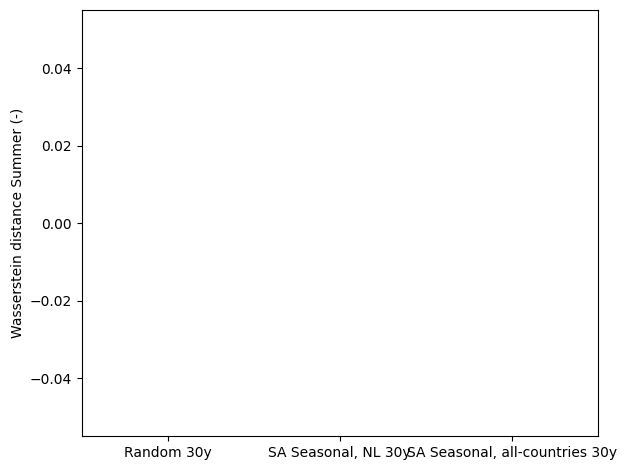

In [21]:
df_wass_seasonal_plot = df_wasserstein_seasonal.query(
    "dataset_type in [@LABEL_RUN_ID_MAIN, @LABEL_RUN_ID_ALTERNATIVE, @LABEL_RUN_ID_MAIN_RANDOM]"
)
order = (
    df_wass_seasonal_plot.groupby("dataset_type")["Wass_summer"]
    .median()
    .sort_values()
    .index.tolist()
)

ax = sns.violinplot(
    data=df_wass_seasonal_plot,
    x="dataset_type",
    y="Wass_summer",
    order=order,
    inner="box",
    cut=0,
)
ax.set_ylabel("Wasserstein distance Summer (-)")
ax.set_xlabel(None)
plt.xticks()
plt.tight_layout()

/usr/people/duinen/04_weather_year_selection/weather_year_selection/lib/python3.11/site-packages/numpy/lib/nanfunctions.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
/usr/people/duinen/04_weather_year_selection/weather_year_selection/lib/python3.11/site-packages/numpy/lib/nanfunctions.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
/usr/people/duinen/04_weather_year_selection/weather_year_selection/lib/python3.11/site-packages/numpy/lib/nanfunctions.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)


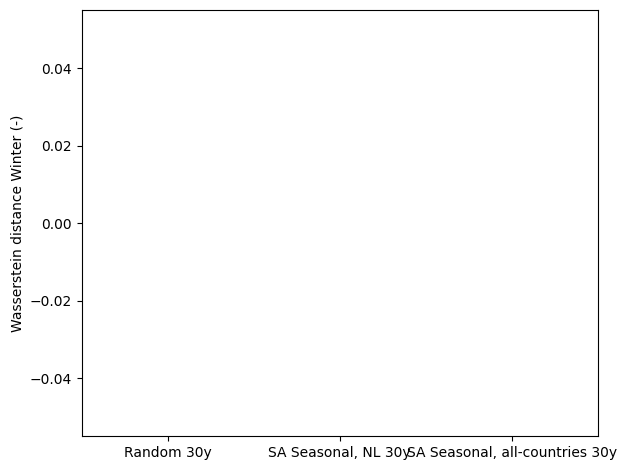

In [22]:
order = (
    df_wass_seasonal_plot.groupby("dataset_type")["Wass_winter"]
    .median()
    .sort_values()
    .index.tolist()
)

ax = sns.violinplot(
    data=df_wass_seasonal_plot,
    x="dataset_type",
    y="Wass_winter",
    order=order,
    inner="box",
    cut=0,
)
ax.set_ylabel("Wasserstein distance Winter (-)")
ax.set_xlabel(None)
plt.xticks()
plt.tight_layout()

In [23]:
df_worst_season = (
    df_wass_seasonal_plot[["Wass_summer", "Wass_winter"]]
    .max(axis=1)
    .to_frame(name="Wass_worst_season")
)
df_worst_season["dataset_type"] = df_wass_seasonal_plot["dataset_type"]

([0, 1, 2],
 [Text(0, 0, 'Random 30y'),
  Text(1, 0, 'SA Seasonal, NL 30y'),
  Text(2, 0, 'SA Seasonal, all-countries 30y')])

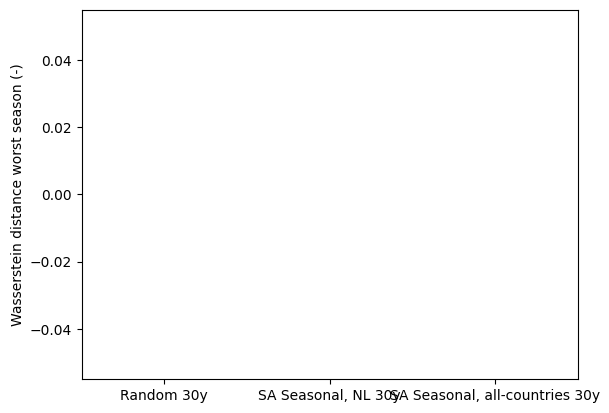

In [24]:
ax = sns.violinplot(
    data=df_worst_season,
    x="dataset_type",
    y="Wass_worst_season",
    order=order,
    inner="box",
    cut=0,
)
ax.set_ylabel("Wasserstein distance worst season (-)")
ax.set_xlabel(None)
plt.xticks()

Text(0, 0.5, 'Wasserstein Winter (-)')

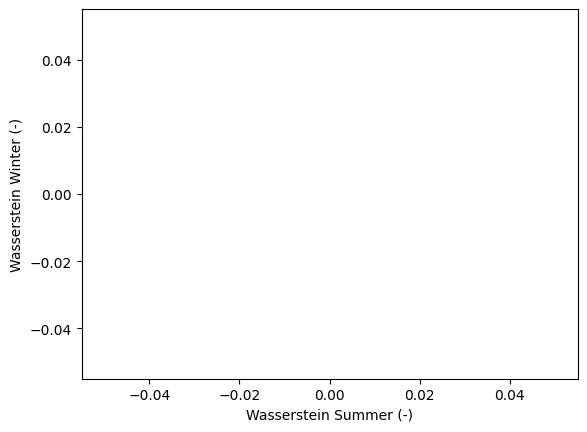

In [25]:
df_wass_alternative = df_wasserstein_seasonal[
    df_wasserstein_seasonal["dataset_type"] == LABEL_RUN_ID_ALTERNATIVE
]
plt.scatter(
    df_wass_alternative["Wass_summer"],
    df_wass_alternative["Wass_winter"],
)
plt.xlabel("Wasserstein Summer (-)")
plt.ylabel("Wasserstein Winter (-)")

## 4.5 Look at impact of subset size

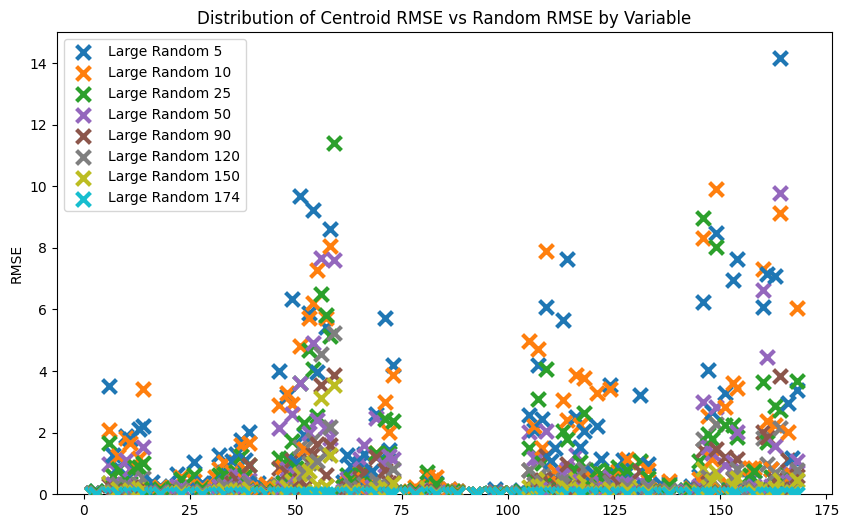

In [26]:
# calculate large random scores

# Get centroid RMSE values for each variable
random_metrics_lr = df_metrics.query("dataset.str.contains('Large Random')")

# Create violin plot of centroid RMSE values
fig, ax = plt.subplots(figsize=(10, 6))

colors = plt.cm.tab10(np.linspace(0, 1, len(sizes)))
for i, var in enumerate(all_vars):
    for j, size in enumerate(sizes):
        rmse = random_metrics_lr.query(
            f"dataset == 'Large Random {size}' and variable == @var"
        )["RMSE"].item()
        ax.scatter(
            i,
            rmse,
            marker="x",
            s=100,
            linewidth=3,
            label=f"Large Random {size}" if i == 0 else "",
            zorder=10,
            color=colors[j],
        )

ax.set_ylim(0, 15)
ax.set_title("Distribution of Centroid RMSE vs Random RMSE by Variable")
ax.set_ylabel("RMSE")
ax.legend()

In [27]:
# k-medoids large-small
centroids_k_medoids_load_large_small = pd.read_csv(
    os.path.join(BASE_OUTPUT, f"centroids/{FNAME_KMEDOIDS_LARGE_SMALL}"), index_col=0
)
centroids_k_medoids_load_large_small_sel = centroids_k_medoids_load_large_small[
    ["model", "Hydrological_year"]
].values

df_k_medoids_large_small = build_df_centroids(
    df_daily, centroids_k_medoids_load_large_small_sel, mode="Hydrological_year"
)

wass_k_medoids_large_small = sliced_wasserstein_distance(
    df_k_medoids_large_small[vars_to_match].to_numpy(),
    ds_ref,
    seed=seed,
    n_projections=50,
)

In [28]:
wass_large_small = df_wasserstein.query(
    "dataset_type in [@LABEL_RUN_ID_LARGE_SMALL_RANDOM, @LABEL_RUN_ID_LARGE_SMALL]"
)

# main SA vs large/small SA
fig, ax = plt.subplots(figsize=(8, 4), dpi=300)

sns.violinplot(
    data=wass_large_small,
    hue="dataset_type",
    x=0,
    y="Wasserstein_distance",
    ax=ax,
    cut=0,
    split=True,
)

ax.scatter(
    0,
    wass_k_medoids_large_small,
    marker="x",
    color="red",
    s=100,
    linewidth=3,
    label="K_medoids",
    zorder=10,
)

handles, labels = ax.get_legend_handles_labels()
labels = ["Simulated Annealing", "Random", "K_medoids"]

sns.violinplot(
    data=wass_main_vs_random,
    hue="dataset_type",
    x=1,
    y="Wasserstein_distance",
    ax=ax,
    cut=0,
    split=True,
)

ax.scatter(
    1,
    df_wasserstein.query("dataset_type == @LABEL_KMEDOIDS")[
        "Wasserstein_distance"
    ].values[0],
    marker="x",
    color="red",
    s=100,
    linewidth=3,
    label="K_medoids",
    zorder=10,
)


# Use only the legend from the first plot
ax.legend(handles, labels, title="Dataset type")

ax.set_ylim(0, 10)
ax.set_xticks([0, 1], ["5 years", "30 years"])
ax.set_xlabel("Subset size (years)")
ax.set_ylabel("Wasserstein distance (-)")

Text(0, 0.5, 'Wasserstein distance (-)')

Error in callback <function _draw_all_if_interactive at 0x7ff96c12fc40> (for post_execute), with arguments args (),kwargs {}:


TypeError: _compat_get_offset.<locals>.<lambda>() missing 2 required positional arguments: 'bbox' and 'renderer'

TypeError: _compat_get_offset.<locals>.<lambda>() missing 2 required positional arguments: 'bbox' and 'renderer'

<Figure size 2400x1200 with 1 Axes>

## 4.6 Individual years also representative?

In [29]:
chosen_modelyears = []
for i in range(len(df_sel_main)):
    chosen_modelyears.extend(eval(df_sel_main["selected"][i]))

In [30]:
# calc wasserstein per modelyear, look for correlation with number of times chosen
modelyear_wass = {}
for model in MODELS:
    for year in tqdm(HYDROLOGICAL_YEARS):
        ds_modelyear = df_daily.query(
            f"model == '{model}' and Hydrological_year == {year}"
        )[vars_to_match].to_numpy()
        wass = sliced_wasserstein_distance(
            ds_modelyear, ds_ref, seed=seed, n_projections=50
        )
        modelyear_wass[(model, year)] = wass

# 45*30 = 1350
# 180 modelyears in total, so on average each modelyear is chosen 7.5 times
modelyear_count = Counter(chosen_modelyears)

  0%|          | 0/29 [00:00<?, ?it/s]

  0%|          | 0/29 [00:00<?, ?it/s]

  0%|          | 0/29 [00:00<?, ?it/s]

  0%|          | 0/29 [00:00<?, ?it/s]

  0%|          | 0/29 [00:00<?, ?it/s]

  0%|          | 0/29 [00:00<?, ?it/s]

In [31]:
rows = []
for model in MODELS:
    for year in HYDROLOGICAL_YEARS:
        rows.append(
            {
                "model": model,
                "year": year,
                "count": int(modelyear_count.get((model, year), 0)),
                "wass": float(modelyear_wass.get((model, year), np.nan)),
            }
        )

df_mw = pd.DataFrame(rows).dropna(subset=["wass"])

# Correlations
rho, p_rho = spearmanr(df_mw["count"], df_mw["wass"])

print(f"Spearman rho = {rho:.3f}, p = {p_rho:.3e}")

Spearman rho = nan, p = nan


(0.0, 0.05500000000000001)

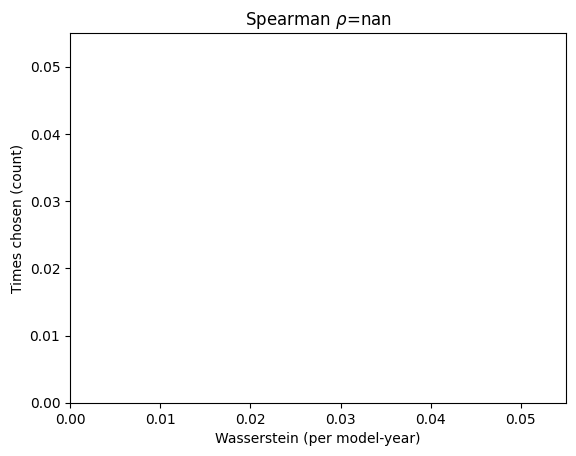

In [32]:
plt.scatter(df_mw["wass"], df_mw["count"])
plt.title(f"Spearman $\\rho$={rho:.3f}")
plt.xlabel("Wasserstein (per model-year)")
plt.ylabel("Times chosen (count)")
plt.xlim(0, None)
plt.ylim(0, None)